# Proyecto final: predicción de devoluciones y reclamos en ventas de Novohome (Mercado Libre)
**Autora:** Elizabeth Luque · **Curso:** Data Science II — Machine Learning para la Ciencia de Datos (Coderhouse)

## Abstracto
Novohome vende artículos para el hogar, pequeños electrodomésticos, grifería y belleza en Mercado Libre. Cada devolución o reclamo tiene un costo directo (envío de ida y vuelta, producto que vuelve a revisión) y otro indirecto: afecta la reputación de la cuenta.
Este proyecto entrena un modelo que estima, **al momento de la venta**, la probabilidad de que la orden termine en devolución o reclamo, para que el equipo comercial pueda actuar antes: confirmar compatibilidad, enviar instrucciones de uso o revisar la publicación.

**Audiencia:** equipo comercial y de e-commerce (uso del modelo) y equipo de datos (reproducción y mantenimiento).

> **Datos:** sintéticos, generados con semilla fija por `src/generar_datos.py`. Imitan la estructura del negocio pero no contienen clientes, órdenes ni códigos de producto reales.

## 1. Preguntas y problema a resolver
| Elemento | Definición |
|---|---|
| Tipo de tarea | **Clasificación binaria** |
| Variable objetivo | `devolucion_o_reclamo` (1 = la orden terminó en devolución o reclamo) |
| Métrica técnica principal | **ROC-AUC** (capacidad de ordenar las órdenes por riesgo) + **PR-AUC** (útil porque la clase positiva es minoritaria) |
| Métrica de negocio | **Ahorro neto** en ARS al contactar preventivamente las órdenes que el modelo marca como riesgosas |
| Momento de predicción | Al confirmarse la venta: solo se pueden usar datos conocidos en ese momento |

**Preguntas:** ¿qué factores se asocian a las devoluciones? ¿Un modelo supera claramente a una regla simple? ¿Cuánto se ahorraría usándolo?

**Supuestos de negocio (editables):** una devolución cuesta en promedio **$18.000** (logística inversa + revisión); un contacto preventivo cuesta **$1.500** y evita el **35%** de las devoluciones de las órdenes contactadas.

In [1]:
import os, sys, sqlite3, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost, shap, joblib
from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from xgboost import XGBClassifier
warnings.filterwarnings("ignore", category=UserWarning)

SEMILLA = 42
COSTO_DEVOLUCION, COSTO_CONTACTO, EFECTIVIDAD_CONTACTO = 18_000, 1_500, 0.35
# Si el notebook se abre solo (por ejemplo, en Colab), descarga el repositorio para tener src/
REPO_URL = "https://github.com/scarletluque0805/proyecto-final-novohome.git"
if not (os.path.exists("src") or os.path.exists("../src")):
    if not os.path.exists("proyecto-final-novohome"):
        os.system(f"git clone -q {REPO_URL}")
    os.chdir("proyecto-final-novohome")
RAIZ = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
DB, FIG, MOD = f"{RAIZ}/data/novohome_ml.db", f"{RAIZ}/reports/figures", f"{RAIZ}/models"
os.makedirs(FIG, exist_ok=True); os.makedirs(MOD, exist_ok=True)
sys.path.insert(0, f"{RAIZ}/src")
print("Versiones -> pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| shap", shap.__version__)

controles = []                       # tabla final esperado vs observado
def chequear(etapa, control, esperado, observado):
    controles.append((etapa, control, str(esperado), str(observado)))

Versiones -> pandas 2.2.3 | scikit-learn 1.6.1 | xgboost 3.4.1 | shap 0.54.1


## 2. Ingesta: generación de datos y extracción con SQL
Los datos se cargan en SQLite en una transacción explícita (`BEGIN` → validación del conteo → `COMMIT`, con `ROLLBACK` ante error) y se extraen con una consulta que une órdenes y productos.

| Tabla | Grano | Clave |
|---|---|---|
| `productos` | un producto publicado | `sku` (código genérico `NH-…`) |
| `ordenes` | una orden de un producto | `orden_id` |

In [2]:
from generar_datos import generar, cargar_sqlite
productos, ordenes = generar()
cargar_sqlite(productos, ordenes, DB)

CONSULTA = '''
SELECT o.*, p.categoria, p.precio_lista, p.fotos, p.puntaje_ficha
FROM ordenes o
JOIN productos p ON p.sku = o.sku          -- cada orden con los atributos de su publicación
ORDER BY o.fecha, o.orden_id
'''
conn = sqlite3.connect(DB)
try:
    df_raw = pd.read_sql_query(CONSULTA, conn, parse_dates=["fecha"])
    sin_producto = conn.execute("SELECT COUNT(*) FROM ordenes o LEFT JOIN productos p ON p.sku=o.sku WHERE p.sku IS NULL").fetchone()[0]
finally:
    conn.close()
print("Filas extraídas:", df_raw.shape, "| órdenes sin producto (anti-join):", sin_producto)
chequear("Ingesta", "Todas las órdenes tienen producto", 0, sin_producto)
chequear("Ingesta", "Filas extraídas = filas cargadas", len(ordenes), len(df_raw))
df_raw.head()

Filas extraídas: (8025, 18) | órdenes sin producto (anti-join): 0


,orden_id,fecha,sku,logistica,region,dias_entrega,descuento_pct,precio_final,cuotas_sin_interes,compras_previas_cliente,cliente_pregunto,evento_comercial,devolucion_o_reclamo,dias_hasta_reclamo,categoria,precio_lista,fotos,puntaje_ficha
0,555,2025-01-01,NH-4022,Full,AMBA,2.0,9.0,18928.0,1,2,0,0,0,NaN,Belleza y cuidado personal,20800.0,12,68.551400
1,628,2025-01-01,NH-2024,Colecta,AMBA,5.0,16.0,16380.0,1,1,0,0,0,NaN,Bazar y cocina,19500.0,10,72.262226
2,634,2025-01-01,NH-5005,Full,AMBA,1.0,12.0,8448.0,0,1,0,0,0,NaN,Organización del hogar,9600.0,12,94.042962
3,1095,2025-01-01,NH-1004,Full,Norte,3.0,2.0,63308.0,0,2,0,0,1,22.0,Pequeños electrodomésticos,64600.0,10,61.763473
4,1405,2025-01-01,NH-3016,Full,AMBA,1.0,14.0,51084.0,0,1,1,0,0,NaN,Grifería y plomería,59400.0,5,73.563294


## 3. Análisis exploratorio de datos (EDA)
### 3.1 Calidad de datos

In [3]:
calidad = pd.DataFrame({"tipo": df_raw.dtypes.astype(str), "nulos": df_raw.isna().sum(), "%_nulos": (df_raw.isna().mean()*100).round(1)})
print(calidad[calidad.nulos > 0])
print("\nÓrdenes duplicadas (orden_id repetido):", df_raw.orden_id.duplicated().sum())
print("Valores de región:", sorted(df_raw.region.unique()))
q1, q3 = df_raw.precio_final.quantile([.25, .75]); lim = q3 + 3 * (q3 - q1)
print(f"Precios por encima de Q3 + 3·IQR (${lim:,.0f}):", (df_raw.precio_final > lim).sum(), "| máximo:", f"${df_raw.precio_final.max():,.0f}")
print(f"\nTasa de devolución/reclamo: {df_raw.devolucion_o_reclamo.mean():.1%}")

                       tipo  nulos  %_nulos
dias_entrega        float64    240      3.0
dias_hasta_reclamo  float64   7439     92.7
puntaje_ficha       float64    326      4.1

Órdenes duplicadas (orden_id repetido): 25
Valores de región: ['AMBA', 'AMBA ', 'CENTRO ', 'CUYO ', 'Centro', 'Cuyo', 'LITORAL ', 'Litoral', 'NORTE ', 'Norte', 'PATAGONIA ', 'Patagonia']
Precios por encima de Q3 + 3·IQR ($122,916): 77 | máximo: $10,587,500

Tasa de devolución/reclamo: 7.3%


**Problemas detectados y decisión:**
- **`dias_hasta_reclamo`** solo tiene valor cuando hubo reclamo: es información del futuro (**data leakage**). Se descarta.
- **25 órdenes duplicadas** → se eliminan (contarían doble).
- **Región con mayúsculas y espacios** → se normaliza.
- **Precios ~100 veces mayores** a su precio de lista (error de carga) → se reemplazan por NaN y se imputan.
- **Nulos en `dias_entrega` y `puntaje_ficha`** → se imputan con la mediana **dentro del pipeline**, ajustada solo con datos de entrenamiento. El tipo de faltante se analiza abajo.

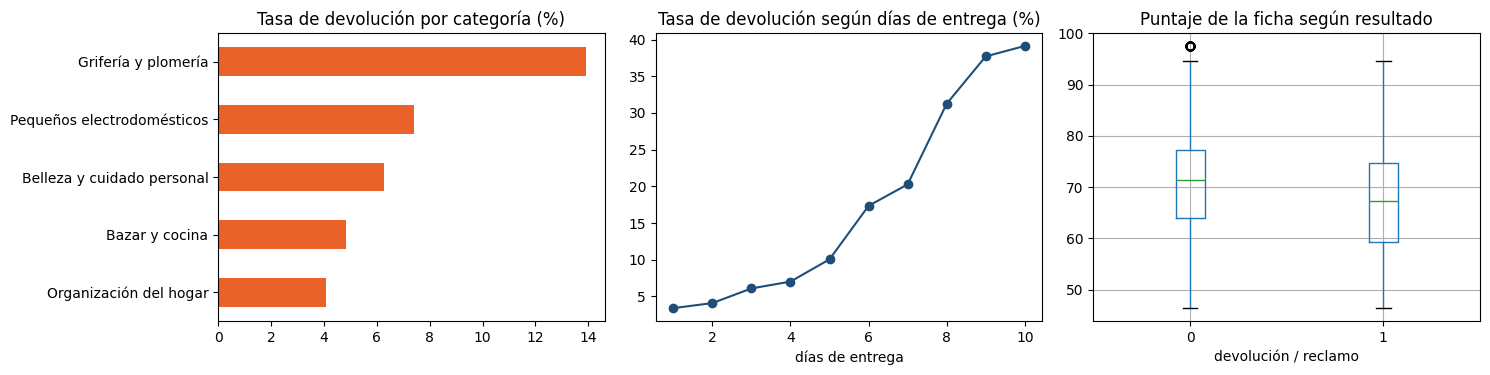

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
tasa_cat = df_raw.groupby("categoria").devolucion_o_reclamo.mean().sort_values()
tasa_cat.mul(100).plot.barh(ax=ax[0], color="#E8622A"); ax[0].set_title("Tasa de devolución por categoría (%)"); ax[0].set_ylabel("")
df_raw.groupby(df_raw.dias_entrega.clip(upper=10)).devolucion_o_reclamo.mean().mul(100).plot(ax=ax[1], marker="o", color="#1F4E79")
ax[1].set_title("Tasa de devolución según días de entrega (%)"); ax[1].set_xlabel("días de entrega")
df_raw.boxplot(column="puntaje_ficha", by="devolucion_o_reclamo", ax=ax[2]); ax[2].set_title("Puntaje de la ficha según resultado"); ax[2].set_xlabel("devolución / reclamo"); fig.suptitle("")
plt.tight_layout(); plt.savefig(f"{FIG}/01_eda_principal.png", dpi=110); plt.show()

            count   mean
ficha_nula              
False        7699  0.073
True          326  0.083

Las fichas sin evaluar tienen una tasa de devolución algo mayor: el faltante podría no ser aleatorio,
así que además de imputar se agrega el indicador 'ficha_sin_puntaje' para que el modelo pueda usarlo.


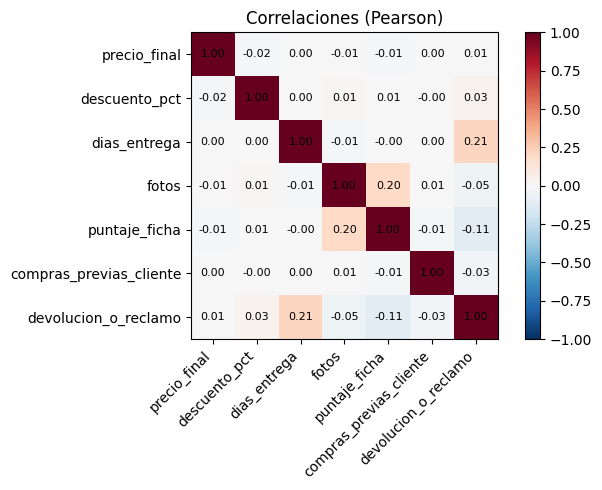

In [5]:
# Tipo de faltante: ¿el nulo de puntaje_ficha se relaciona con el resultado? (MCAR vs MAR/MNAR)
tabla_nulos = df_raw.assign(ficha_nula=df_raw.puntaje_ficha.isna()).groupby("ficha_nula").devolucion_o_reclamo.agg(["count", "mean"])
print(tabla_nulos.round(3))
print("\nLas fichas sin evaluar tienen una tasa de devolución algo mayor: el faltante podría no ser aleatorio,")
print("así que además de imputar se agrega el indicador 'ficha_sin_puntaje' para que el modelo pueda usarlo.")
num = ["precio_final", "descuento_pct", "dias_entrega", "fotos", "puntaje_ficha", "compras_previas_cliente"]
corr = df_raw[num + ["devolucion_o_reclamo"]].corr()
fig, ax = plt.subplots(figsize=(7, 5)); im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right"); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im); ax.set_title("Correlaciones (Pearson)"); plt.tight_layout(); plt.savefig(f"{FIG}/02_correlaciones.png", dpi=110); plt.show()

**Insights del EDA:**
- **Grifería y plomería** tiene la tasa de devolución más alta: en estos productos la compatibilidad (medidas, roscas) genera errores de compra.
- La tasa **sube con los días de entrega**, sobre todo a partir de 5 días.
- Las publicaciones con **mejor puntaje de ficha** tienen menos devoluciones: una ficha completa reduce las compras equivocadas.
- No hay correlaciones fuertes entre variables numéricas (sin multicolinealidad grave). Las relaciones son débiles por separado, lo que sugiere probar modelos que capten combinaciones (árboles y boosting).

## 4. Ingeniería de atributos

In [6]:
df = df_raw.drop(columns=["dias_hasta_reclamo"]).drop_duplicates(subset="orden_id").copy()   # fuga + duplicados
df["region"] = df.region.str.strip().str.title().replace({"Amba": "AMBA"})
df.loc[df.precio_final > df.precio_lista * 1.5, "precio_final"] = np.nan                     # error de carga -> NaN

# Variables nuevas (todas conocidas al momento de la venta)
df["mes"] = df.fecha.dt.month
df["fin_de_semana"] = (df.fecha.dt.dayofweek >= 5).astype(int)
df["ficha_sin_puntaje"] = df.puntaje_ficha.isna().astype(int)
df["pocas_fotos"] = (df.fotos < 6).astype(int)
df["descuento_alto"] = (df.descuento_pct > 30).astype(int)
df["log_precio"] = np.log1p(df.precio_final)                       # el precio es muy asimétrico
df["cliente_nuevo"] = (df.compras_previas_cliente == 0).astype(int)
df["envio_lejano"] = df.region.isin(["Norte", "Cuyo", "Patagonia"]).astype(int)

NUM = ["log_precio", "descuento_pct", "dias_entrega", "fotos", "puntaje_ficha", "compras_previas_cliente", "mes"]
BIN = ["cuotas_sin_interes", "cliente_pregunto", "evento_comercial", "fin_de_semana", "ficha_sin_puntaje",
       "pocas_fotos", "descuento_alto", "cliente_nuevo", "envio_lejano"]
CAT = ["categoria", "logistica", "region"]
OBJ = "devolucion_o_reclamo"

print("Filas tras limpieza:", len(df), "| regiones:", sorted(df.region.unique()))
chequear("Limpieza", "Sin órdenes duplicadas", 0, df.orden_id.duplicated().sum())
chequear("Limpieza", "Columna con fuga eliminada", False, "dias_hasta_reclamo" in df.columns)
chequear("Limpieza", "6 regiones tras normalizar", 6, df.region.nunique())

Filas tras limpieza: 8000 | regiones: ['AMBA', 'Centro', 'Cuyo', 'Litoral', 'Norte', 'Patagonia']


**División temporal** (más realista que una división al azar: el modelo se usa sobre ventas futuras):
- **Entrenamiento:** enero a diciembre de 2025.
- **Validación:** enero a marzo de 2026. Se usa para elegir el modelo y el umbral.
- **Test:** abril a junio de 2026. Se usa una sola vez, al final.

**Preprocesamiento dentro de un `Pipeline`:** imputación con mediana + estandarización para las numéricas, y one-hot para las categóricas. Así se ajusta solo con entrenamiento y no hay fuga de información.

In [7]:
train = df[df.fecha < "2026-01-01"]; val = df[(df.fecha >= "2026-01-01") & (df.fecha < "2026-04-01")]; test = df[df.fecha >= "2026-04-01"]
X_tr, y_tr = train[NUM + BIN + CAT], train[OBJ]; X_va, y_va = val[NUM + BIN + CAT], val[OBJ]; X_te, y_te = test[NUM + BIN + CAT], test[OBJ]
print(pd.DataFrame({"filas": [len(train), len(val), len(test)], "tasa_positivos": [y_tr.mean(), y_va.mean(), y_te.mean()]},
                   index=["train", "validación", "test"]).round(3))
chequear("Split", "Sin solapamiento temporal", True, train.fecha.max() < val.fecha.min() and val.fecha.max() < test.fecha.min())

def preprocesador(escalar=True):
    numerico = [("imp", SimpleImputer(strategy="median"))] + ([("esc", StandardScaler())] if escalar else [])
    return ColumnTransformer([("num", Pipeline(numerico), NUM), ("bin", "passthrough", BIN),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])

            filas  tasa_positivos
train        5417           0.072
validación   1286           0.072
test         1297           0.079


## 5. Entrenamiento y comparación de modelos (validación cruzada estratificada, 5 folds sobre train)

In [8]:
peso = (y_tr == 0).sum() / (y_tr == 1).sum()          # compensa el desbalance de clases
modelos = {
    "Regresión logística": Pipeline([("prep", preprocesador()), ("m", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Random Forest": Pipeline([("prep", preprocesador(False)), ("m", RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                class_weight="balanced", n_jobs=-1, random_state=SEMILLA))]),
    "XGBoost": Pipeline([("prep", preprocesador(False)), ("m", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                          subsample=0.8, colsample_bytree=0.8, scale_pos_weight=peso, eval_metric="logloss", random_state=SEMILLA, n_jobs=-1))]),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = []
for nombre, modelo in modelos.items():
    t0 = time.perf_counter()
    r = cross_validate(modelo, X_tr, y_tr, cv=cv, scoring=["roc_auc", "average_precision"])
    modelo.fit(X_tr, y_tr); p = modelo.predict_proba(X_va)[:, 1]
    filas.append({"modelo": nombre, "ROC-AUC CV": r["test_roc_auc"].mean(), "± CV": r["test_roc_auc"].std(),
                  "PR-AUC CV": r["test_average_precision"].mean(), "ROC-AUC val": roc_auc_score(y_va, p),
                  "PR-AUC val": average_precision_score(y_va, p), "segundos": time.perf_counter() - t0})
# Línea base: regla simple de negocio (marcar grifería o entregas de más de 5 días)
regla = ((X_va.categoria == "Grifería y plomería") | (X_va.dias_entrega > 5)).astype(int)
filas.append({"modelo": "Regla simple (línea base)", "ROC-AUC val": roc_auc_score(y_va, regla), "PR-AUC val": average_precision_score(y_va, regla)})
comparacion = pd.DataFrame(filas).set_index("modelo").round(3)
print(comparacion.to_string())

                           ROC-AUC CV   ± CV  PR-AUC CV  ROC-AUC val  PR-AUC val  segundos
modelo                                                                                    
Regresión logística             0.753  0.021      0.257        0.795       0.313     1.122
Random Forest                   0.748  0.020      0.248        0.764       0.278    19.279
XGBoost                         0.725  0.019      0.203        0.725       0.235     1.934
Regla simple (línea base)         NaN    NaN        NaN        0.705       0.136       NaN


## 6. Optimización de hiperparámetros (RandomizedSearchCV sobre XGBoost)

In [9]:
espacio = {"m__n_estimators": [200, 300, 500], "m__max_depth": [2, 3, 4, 5], "m__learning_rate": [0.02, 0.05, 0.1],
           "m__min_child_weight": [1, 5, 10], "m__subsample": [0.7, 0.8, 1.0], "m__colsample_bytree": [0.6, 0.8, 1.0],
           "m__reg_lambda": [1, 5, 10]}
busqueda = RandomizedSearchCV(modelos["XGBoost"], espacio, n_iter=20, scoring="roc_auc", cv=cv, random_state=SEMILLA, n_jobs=-1)
t0 = time.perf_counter(); busqueda.fit(X_tr, y_tr)
xgb_opt = busqueda.best_estimator_; p_opt = xgb_opt.predict_proba(X_va)[:, 1]
print(f"Búsqueda: 20 combinaciones × 5 folds en {time.perf_counter() - t0:.0f} s")
print("Mejores hiperparámetros:", {k.replace("m__", ""): v for k, v in busqueda.best_params_.items()})
print(f"ROC-AUC CV: {busqueda.best_score_:.3f} | ROC-AUC validación: {roc_auc_score(y_va, p_opt):.3f} (antes: {comparacion.loc['XGBoost', 'ROC-AUC val']:.3f})")
comparacion.loc["XGBoost optimizado", ["ROC-AUC CV", "ROC-AUC val", "PR-AUC val"]] = [round(busqueda.best_score_, 3),
    round(roc_auc_score(y_va, p_opt), 3), round(average_precision_score(y_va, p_opt), 3)]

Búsqueda: 20 combinaciones × 5 folds en 36 s
Mejores hiperparámetros: {'subsample': 0.7, 'reg_lambda': 10, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 2, 'learning_rate': 0.05, 'colsample_bytree': 0.6}
ROC-AUC CV: 0.749 | ROC-AUC validación: 0.795 (antes: 0.725)


## 7. Selección del modelo con criterio de negocio
Se elige el umbral de probabilidad que **maximiza el ahorro neto en validación**. Contactar una orden cuesta $1.500; si la orden iba a devolverse, el contacto evita la devolución el 35% de las veces y ahorra $18.000.

In [10]:
def ahorro(y, prob, umbral):
    marcadas = prob >= umbral
    evitadas = EFECTIVIDAD_CONTACTO * (marcadas & (y == 1)).sum()
    return evitadas * COSTO_DEVOLUCION - marcadas.sum() * COSTO_CONTACTO

umbrales = np.round(np.arange(0.05, 0.95, 0.01), 2)
candidatos = {"Regresión logística": modelos["Regresión logística"], "Random Forest": modelos["Random Forest"], "XGBoost optimizado": xgb_opt}
resumen = []
for nombre, m in candidatos.items():
    p = m.predict_proba(X_va)[:, 1]; a = [ahorro(y_va.values, p, u) for u in umbrales]
    resumen.append({"modelo": nombre, "ROC-AUC val": roc_auc_score(y_va, p), "umbral óptimo": umbrales[int(np.argmax(a))], "ahorro val (ARS)": max(a)})
resumen = pd.DataFrame(resumen).set_index("modelo").round(3)
print(resumen.to_string())
elegido = resumen["ahorro val (ARS)"].idxmax(); UMBRAL = float(resumen.loc[elegido, "umbral óptimo"]); modelo_final = candidatos[elegido]
print(f"\nModelo elegido: {elegido} (umbral {UMBRAL})")

                     ROC-AUC val  umbral óptimo  ahorro val (ARS)
modelo                                                           
Regresión logística        0.795           0.76           83100.0
Random Forest              0.764           0.62           71100.0
XGBoost optimizado         0.795           0.68           84900.0

Modelo elegido: XGBoost optimizado (umbral 0.68)


**Justificación:** se prioriza el modelo que da **mayor ahorro** en validación, siempre que su ROC-AUC sea competitiva. Ante resultados parecidos, la regresión logística tiene la ventaja de ser más simple y fácil de explicar. SHAP permite explicar también el modelo de boosting.

## 8. Evaluación final en test (se usa una sola vez)

ROC-AUC                  0.721
PR-AUC                   0.252
órdenes marcadas         130
% marcadas               0.100
precisión                0.269
recall                   0.343
ahorro neto test (ARS)   25,500

Interpretación: contactando el 10% de las órdenes se alcanza el 34% de las devoluciones.


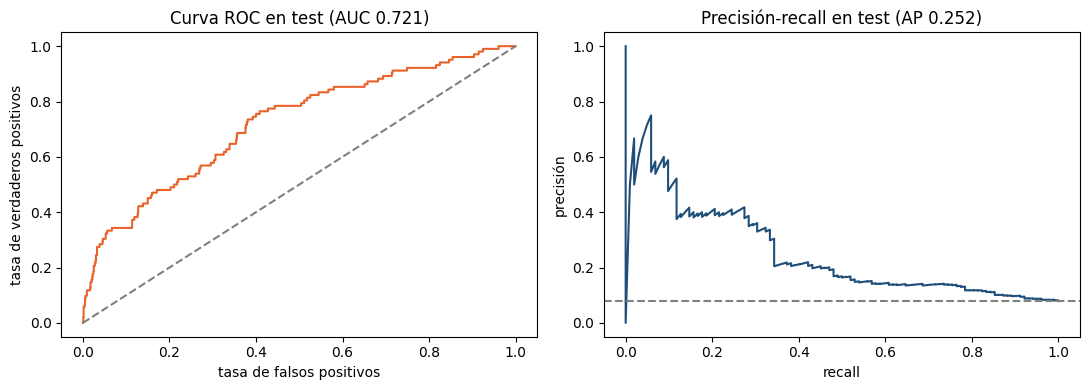

In [11]:
p_te = modelo_final.predict_proba(X_te)[:, 1]
marc = p_te >= UMBRAL
res_test = {"ROC-AUC": roc_auc_score(y_te, p_te), "PR-AUC": average_precision_score(y_te, p_te),
            "órdenes marcadas": int(marc.sum()), "% marcadas": marc.mean(), "precisión": y_te[marc].mean(),
            "recall": (marc & (y_te == 1)).sum() / (y_te == 1).sum(), "ahorro neto test (ARS)": ahorro(y_te.values, p_te, UMBRAL)}
for k, v in res_test.items():
    print(f"{k:<24} {v:,.3f}" if isinstance(v, float) and v < 10 else f"{k:<24} {v:,.0f}")
print(f"\nInterpretación: contactando el {res_test['% marcadas']:.0%} de las órdenes se alcanza el {res_test['recall']:.0%} de las devoluciones.")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
fpr, tpr, _ = roc_curve(y_te, p_te); ax[0].plot(fpr, tpr, color="#E8622A"); ax[0].plot([0, 1], [0, 1], "--", color="grey")
ax[0].set_title(f"Curva ROC en test (AUC {res_test['ROC-AUC']:.3f})"); ax[0].set_xlabel("tasa de falsos positivos"); ax[0].set_ylabel("tasa de verdaderos positivos")
pr, rc, _ = precision_recall_curve(y_te, p_te); ax[1].plot(rc, pr, color="#1F4E79"); ax[1].axhline(y_te.mean(), ls="--", color="grey")
ax[1].set_title(f"Precisión-recall en test (AP {res_test['PR-AUC']:.3f})"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precisión")
plt.tight_layout(); plt.savefig(f"{FIG}/03_curvas_test.png", dpi=110); plt.show()
chequear("Test", "ROC-AUC en test > regla simple", True, bool(res_test["ROC-AUC"] > comparacion.loc["Regla simple (línea base)", "ROC-AUC val"]))
chequear("Test", "Ahorro neto en test positivo", True, bool(res_test["ahorro neto test (ARS)"] > 0))

## 9. Explicabilidad con SHAP

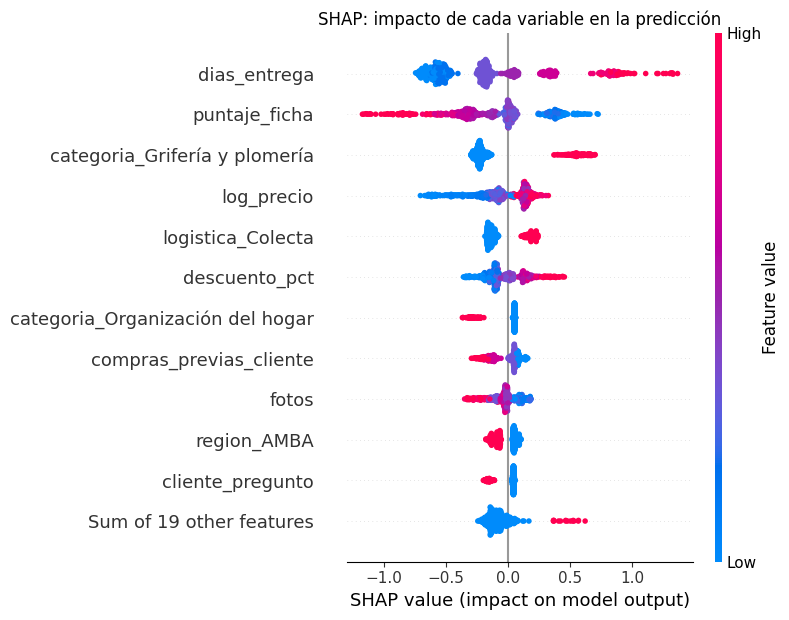

Top 8 variables por |SHAP| medio:
dias_entrega                        0.448
puntaje_ficha                       0.296
categoria_Grifería y plomería       0.290
log_precio                          0.177
logistica_Colecta                   0.155
descuento_pct                       0.131
categoria_Organización del hogar    0.097
compras_previas_cliente             0.096


In [12]:
prep = modelo_final.named_steps["prep"]; est = modelo_final.named_steps["m"]
nombres = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
X_shap = pd.DataFrame(prep.transform(X_te.sample(600, random_state=SEMILLA)), columns=nombres).astype(float)
if isinstance(est, LogisticRegression):
    explicador = shap.LinearExplainer(est, pd.DataFrame(prep.transform(X_tr), columns=nombres).astype(float))
else:
    explicador = shap.TreeExplainer(est)
sv = explicador(X_shap)
if sv.values.ndim == 3:                       # Random Forest devuelve una matriz por clase: nos quedamos con la clase 1
    sv = sv[:, :, 1]
plt.figure(); shap.plots.beeswarm(sv, max_display=12, show=False); plt.title("SHAP: impacto de cada variable en la predicción")
plt.tight_layout(); plt.savefig(f"{FIG}/04_shap_beeswarm.png", dpi=110, bbox_inches="tight"); plt.show()
importancia = pd.Series(np.abs(sv.values).mean(0), index=nombres).sort_values(ascending=False)
print("Top 8 variables por |SHAP| medio:"); print(importancia.head(8).round(3).to_string())
chequear("SHAP", "Grifería y plomería entre las 8 variables más influyentes", True, "categoria_Grifería y plomería" in importancia.head(8).index)

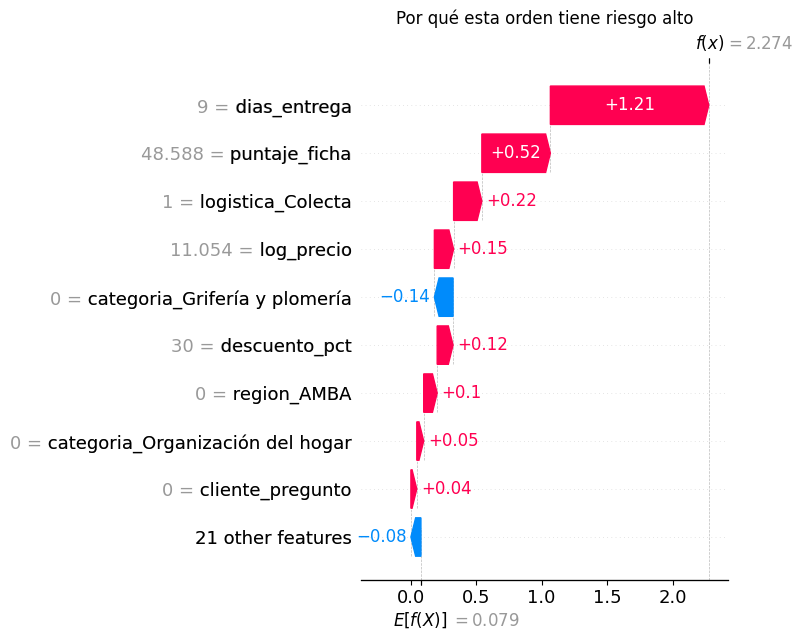

In [13]:
# Explicación de una orden concreta: la de mayor riesgo del test
i = int(np.argmax(sv.values.sum(1)))
plt.figure(); shap.plots.waterfall(sv[i], max_display=10, show=False); plt.title("Por qué esta orden tiene riesgo alto")
plt.tight_layout(); plt.savefig(f"{FIG}/05_shap_orden.png", dpi=110, bbox_inches="tight"); plt.show()

## 10. Guardado del modelo y verificación final

In [14]:
joblib.dump({"modelo": modelo_final, "umbral": UMBRAL, "variables": NUM + BIN + CAT}, f"{MOD}/modelo_devoluciones.joblib")
recargado = joblib.load(f"{MOD}/modelo_devoluciones.joblib")
chequear("Modelo", "El modelo guardado predice igual", True, bool(np.allclose(recargado["modelo"].predict_proba(X_te)[:, 1], p_te)))
# Reproducibilidad: regenerar los datos da exactamente el mismo dataset
p2, o2 = generar()
chequear("Reproducibilidad", "Los datos regenerados son idénticos", True, bool(o2.equals(ordenes) and p2.equals(productos)))
tabla = pd.DataFrame(controles, columns=["etapa", "control", "esperado", "observado"])
tabla["ok"] = np.where(tabla.esperado == tabla.observado, "sí", "NO")
print(tabla.to_string(index=False)); print(f"\n{(tabla.ok == 'sí').sum()}/{len(tabla)} controles OK")
assert (tabla.ok == "sí").all()

           etapa                                                   control esperado observado ok
         Ingesta                         Todas las órdenes tienen producto        0         0 sí
         Ingesta                          Filas extraídas = filas cargadas     8025      8025 sí
        Limpieza                                    Sin órdenes duplicadas        0         0 sí
        Limpieza                                Columna con fuga eliminada    False     False sí
        Limpieza                                6 regiones tras normalizar        6         6 sí
           Split                                 Sin solapamiento temporal     True      True sí
            Test                            ROC-AUC en test > regla simple     True      True sí
            Test                              Ahorro neto en test positivo     True      True sí
            SHAP Grifería y plomería entre las 8 variables más influyentes     True      True sí
          Modelo              

## 11. Conclusiones y recomendaciones
- **El problema es predecible en parte:** los modelos superan a la regla simple de negocio (ROC-AUC 0,72–0,80 contra 0,70) y el elegido genera ahorro neto en un período que no vio durante el entrenamiento (test). El ahorro es moderado, porque con los costos supuestos solo conviene contactar las órdenes de riesgo muy alto.
- **Regresión logística y XGBoost optimizado quedan prácticamente empatados:** la búsqueda de hiperparámetros llevó a XGBoost de 0,725 a 0,795 de ROC-AUC en validación. Si se prefiere simplicidad, la regresión logística es una alternativa casi equivalente.
- **Factores principales (SHAP):** días de entrega, puntaje de la ficha, categoría grifería y plomería, precio, logística por Colecta y nivel de descuento.
- **Acciones sugeridas:**
  - mejorar fichas y fotos de grifería (medidas y compatibilidad bien visibles);
  - priorizar envío Full en las zonas lejanas;
  - contactar preventivamente las órdenes marcadas por el modelo.
- **Limitaciones:** los datos son sintéticos y los costos son supuestos editables. Con datos reales habría que recalibrar el umbral, revisar periódicamente el desempeño (las devoluciones cambian con la estacionalidad) y medir la efectividad real del contacto con una prueba A/B.